In [1]:
import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from scipy import stats, signal
import matplotlib.pyplot as plt
from scipy.optimize import brentq

Text(-0.05, 1.02, '(c)')

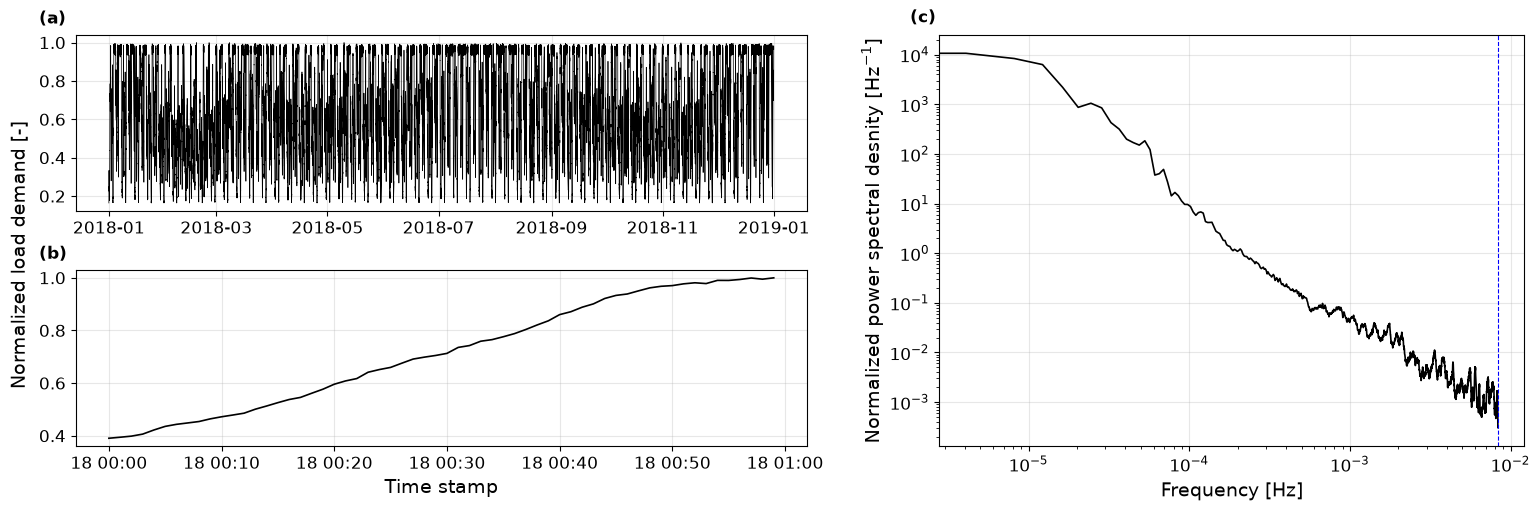

In [2]:
"Generate facility-aggregated profile figure"
# Put your referenced DC data path
df_whole = pd.read_csv('../Results/DCdemand/colocation_10MW_2840nodes_60u_power.csv')

power = df_whole["power_W"].to_numpy()
power = power/np.max(power[:])
df_whole["timestamp"] = pd.to_datetime(df_whole["timestamp"])
time = df_whole["timestamp"].to_numpy()

f, psd = signal.welch(power/power.mean(), 1/60, nperseg=4096)

fig = plt.figure(figsize=(15, 5), constrained_layout=True)
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1.0, 0.8],
    height_ratios=[1, 1],
    wspace = 0.05
)

plt.rcParams.update({
    "font.size": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

ax_time1 = fig.add_subplot(gs[0, 0])
ax_time2 = fig.add_subplot(gs[1, 0])
ax_psd = fig.add_subplot(gs[:, 1])

ax_time1.plot(time, power, lw=0.5, color='k')
ax_time1.grid(alpha=0.3)

ax_time2.plot(time[69120:69180], power[69120:69180], lw=1.2, color='k') # For 1-hr zoom
ax_time2.set_xlabel("Time stamp")
ax_time2.grid(alpha=0.3)

fig.text(
    -0.01, 0.5,
    "Normalized load demand [-]",
    rotation=90,
    va="center",
    ha="center"
)

ax_psd.loglog(f, psd, lw=1.2, color='k', label="Facility-aggregated profile")
ax_psd.set_xlabel("Frequency [Hz]")
ax_psd.set_ylabel("Normalized power spectral desnity [Hz$^{-1}$]")
ax_psd.axvline(1/120, color='b', lw=0.8, ls='--', label='Nyquist limit (60-s sampling)')
ax_psd.grid(alpha=0.3)

ax_time1.text(
    -0.05, 1.04, "(a)",
    transform=ax_time1.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="left"
)

ax_time2.text(
    -0.05, 1.04, "(b)",
    transform=ax_time2.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="left"
)

ax_psd.text(
    -0.05, 1.02, "(c)",
    transform=ax_psd.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="left"
)

# fig.savefig("AggregatedLoad.svg", bbox_inches="tight")

In [3]:
"Construct transition/duration matrix from individual workload for SMM input"

parNum = np.arange(0,21)    # 0~20: llama2-training cases
K = 3
meanSet = np.zeros([len(parNum), K])
stdSet = np.zeros([len(parNum), K]) 
DSet = []
durMatSet = []
tranMatSet = []
observationSet = []
timeSet = []
trim_idxSet = []
labelSet = []

for n, dataNum in enumerate(parNum):
    # Put your referenced DC data path
    df = pd.read_parquet(f'../Results/DCdemand/01_aggregated_datasets/training/results/{dataNum:06d}.parquet')

    time = df.index.to_numpy(dtype=float)
    observations = df["power[W]"].to_numpy(dtype=float)
    trim_idx = time>=0
    observations = observations[trim_idx]/np.max(observations[trim_idx])
    X = observations.reshape(-1,1)
    observationSet.append(observations)
    timeSet.append(time)
    trim_idxSet.append(trim_idx)

    gmm = GaussianMixture(n_components=K, n_init=5, random_state=0).fit(X)
    idx = np.argsort(gmm.means_.flatten())  # sort index since gmm gives random sequence 
    means = gmm.means_.flatten()[idx]
    std = np.sqrt(gmm.covariances_.flatten())[idx]
    meanSet[n] = means
    stdSet[n] = std
    remap = {idx[i]:i for i in range(K)}    # map from random state to sorted state
    labels = np.array([remap[l] for l in gmm.predict(X)])   # sorted labels
    labelSet.append(labels)

    # calculates duration timestep of given state s
    def calculate_duration_timestep(s, labels):    
        count = 0
        count_set = False
        counts = []
        for l in labels:
            if s == l:
                count_set = True    # toggle on for counting
                count+=1            # cumulative counts in the current segment
            elif count_set and s != l: # indicates state change
                counts.append(count)
                count = 0
                count_set = False
        if count_set:   # to account for the case when singal ends with s==l
            counts.append(count)
        return np.array(counts)

    # calculates duration time
    total_count = 0
    dt = 0.2
    time_duration = []
    for s in range(K):
        counts = calculate_duration_timestep(s, labels)
        time_duration.append(dt*counts)

    # calcualtes duration matrix
    dmax = 600  # parquets have different maximum time_duration. So manually assign maximum value so that all cases have same durmat dimensions
    durMatSet.append(np.zeros([K,dmax]))
    for s in range(K):
        c = calculate_duration_timestep(s, labels)
        hist = np.bincount(c, minlength=dmax+1)[1:dmax+1]
        durMatSet[n][s] = hist/hist.sum()

    # calcualtes transition matrix
    tranMatSet.append(np.zeros([K,K]))
    prev = labels[0]
    for s in labels[1:]:
        if s != prev:
            tranMatSet[n][prev,s] += 1
            prev = s
    np.fill_diagonal(tranMatSet[n], 0)
    tranMatSet[n] = tranMatSet[n]/tranMatSet[n].sum(axis=1)[:, np.newaxis]
            
    ### Uncomment to plot histogram of duration time for each case
    # fig, axes = plt.subplots(K, 1, figsize=(12, 8))
    # for i, ax in enumerate(axes.flat):
    #     d = time_duration[i]
    #     ax.hist(d, bins=50, edgecolor='white', alpha=0.8)
    #     ax.axvline(d.mean(), color='red', ls='--', label=f'mean={d.mean():.1f}s')
    #     ax.axvline(d.std(), color='blue', ls='--', label=f'std={d.std():.1f}s')
    #     ax.set_title(f'{dataNum}parquet, state {i} (n={len(d)})')
    #     ax.set_xlabel('duration time [s]'); ax.set_ylabel('count')
    #     ax.legend()
    # plt.tight_layout()
    # plt.show()

# average of the 21sets
tranMatAvg = np.mean(tranMatSet, axis=0)
durMatAvg = np.mean(durMatSet, axis=0)
meanAvg = np.mean(meanSet, axis=0)
stdAvg = np.mean(stdSet, axis=0)

del DSet, durMatSet, tranMatSet

In [4]:
"Function for SMM with Ornstein-Uhlenbeck noise"
def sample_smm_ou(means, stds, tmat, dur_mat, n_samples, dt, theta = 0.8, seedNum=None, allowedStates=None):
    if seedNum is not None: np.random.seed(seedNum)
    K = len(means)
    D = dur_mat.shape[1]
    sig = np.zeros(n_samples)
    state_hist = np.zeros(n_samples, dtype=int)

    # state = np.random.choice(K) # initial random state
    if allowedStates is None:
        allowedStates = np.arange(K)
    state = np.random.choice(allowedStates) # initial random state

    i = 0
    while i < n_samples:
        dur = np.random.choice(D, p=dur_mat[state]) + 1 # select duration time based on duration matrix
        dur = min(dur, n_samples - i)   # when dur < remaining time steps
        x = 0.0
        sigma = stds[state] * np.sqrt(2*theta)  # sigma_eq = sigma_OU/sqrt(2theta)
        for k in np.arange(0, dur):
            x += -theta*x*dt + sigma*np.sqrt(dt)*np.random.randn()
            sig[i+k] = means[state] + x
            state_hist[i+k] = state
        i += dur

        p = tmat[state].copy()  # tmat[state] returns reference. .copy() is necessary for copy
        mask = np.zeros(K, dtype=bool)
        mask[allowedStates] = True
        p[~mask] = 0.0
        p /= p.sum()
        state = np.random.choice(K, p=p)
    return sig, state_hist


"Generate fast signals with N aggregation"
def generate_fast(N, L, means, stds, tmat, dur_mat, dt, theta=0.8, seedNum=None, allowedStates=None):
    if seedNum is not None:
        np.random.seed(seedNum)

    agg = np.zeros(L)
    for _ in range(N):
        sig, _ = sample_smm_ou(means=means, stds=stds, tmat=tmat, dur_mat=dur_mat, n_samples=L, dt=dt, theta=theta, allowedStates=allowedStates)
        agg += sig
    agg /= N    # N aggregation
    delta = (agg - agg.mean()) / agg.mean() # avg = 0, relative variations
    return delta

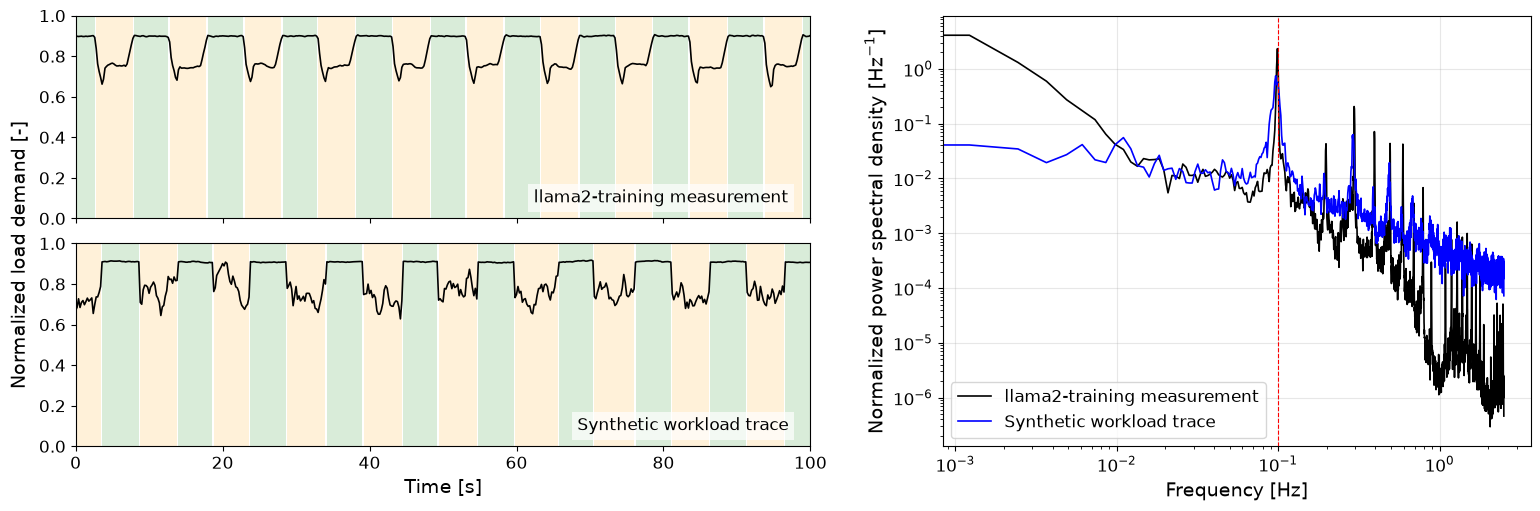

In [5]:
"Compare original and SMM-reconstructed signals"

plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

setNum = 0
orig_state = labelSet[setNum]
new_obs, new_state = sample_smm_ou(means=meanAvg, stds=stdAvg, tmat=tranMatAvg, dur_mat=durMatAvg, n_samples=len(observationSet[setNum]), dt=dt, allowedStates=[1,2], seedNum=5)

fig = plt.figure(figsize=(15, 5), constrained_layout=True)
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1.0, 0.8],
    height_ratios=[1, 1],
    wspace = 0.05
)

# left column
ax_time1 = fig.add_subplot(gs[0, 0])
ax_time2 = fig.add_subplot(gs[1, 0], sharex=ax_time1)

# right column: span both rows
ax_psd = fig.add_subplot(gs[:, 1])

ax_time1.plot(timeSet[setNum][trim_idxSet[setNum]]-2500, observationSet[setNum]-0.08, lw=1.2, color='k')
ax_time1.set_ylim([0,1])
ax_time1.tick_params(labelbottom=False)

ax_time2.plot(timeSet[setNum][trim_idxSet[setNum]]-2500, new_obs-0.08, lw=1.2, color='k')
ax_time2.set_xlim([0,100])
ax_time2.set_ylim([0,1])
ax_time2.set_xlabel("Time [s]")

fig.text(
    -0.01, 0.5,
    "Normalized load demand [-]",
    fontsize=14,
    rotation=90,
    va="center",
    ha="center"
)

# state colors
state_colors = {
    0: "gray",
    1: "orange",
    2: "green"
}

def shade_states(ax, time, states, colors, alpha=0.15):

    start = 0
    for i in range(1, len(states)+1):
        if i == len(states) or states[i] != states[start]:
            s = states[start]
            ax.axvspan(
                time[start],
                time[i-1],
                color=colors[s],
                alpha=alpha,
                linewidth=0
            )
            start = i

shade_states(
    ax_time1,
    timeSet[setNum][trim_idxSet[setNum]]-2500,
    orig_state,
    state_colors
)

shade_states(
    ax_time2,
    timeSet[setNum][trim_idxSet[setNum]]-2500,
    new_state,
    state_colors
)

ax_time1.text(
    0.97, 0.06, "llama2-training measurement",
    transform=ax_time1.transAxes,
    ha="right",
    va="bottom",
    fontsize=12,
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
)

ax_time2.text(
    0.97, 0.06, "Synthetic workload trace",
    transform=ax_time2.transAxes,
    ha="right",
    va="bottom",
    fontsize=12,
    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none")
)

fs = 1/dt  # 0.2s resolution
f_original, psd_original = signal.welch(observationSet[setNum]/observationSet[setNum].mean(), fs=fs, nperseg=4096)
f_new, psd_new= signal.welch(new_obs/new_obs.mean(), fs=fs, nperseg=4096)
ax_psd.loglog(f_original, psd_original, color="k", lw=1.2, label="llama2-training measurement")
ax_psd.loglog(f_new, psd_new, color="b", lw=1.2, label="Synthetic workload trace")
ax_psd.grid(alpha=0.3)
ax_psd.set_xlabel("Frequency [Hz]")
ax_psd.set_ylabel('Normalized power spectral density [Hz$^{-1}$]')
ax_psd.axvline(1/10, color='r', lw=0.8, ls='--')
ax_psd.legend()

# fig.savefig("llama_synthetic.pdf", bbox_inches="tight")

top 5 intervals

2018-05-27 09:30:00 4710.360970469492
2018-05-27 09:20:00 4608.650241014611
2018-05-27 09:35:00 4588.310119558276
2018-05-27 09:10:00 4523.423107879871
2018-05-27 09:25:00 4501.872116543968


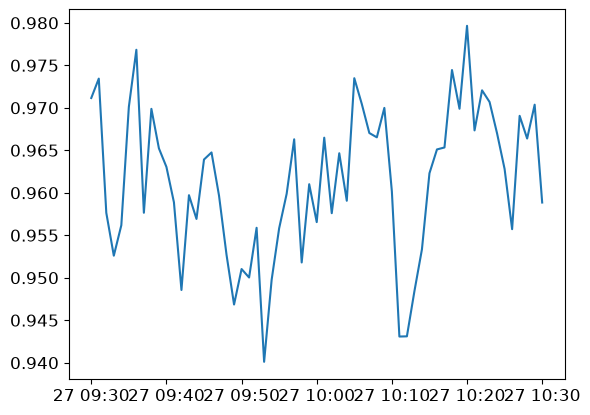

In [ ]:
"Find 60-min base load interval where absolute cummulative gradient change is maximum"
TIMEWINDOW = 60
TIMEINTERVAL = 15

# Put your referenced DC data path
df_base = pd.read_csv('../Results/DCdemand/colocation_10MW_2840nodes_60u_power.csv')
df_base["timestamp"] = pd.to_datetime(df_base["timestamp"]) # str to datetime64 object
df_base = df_base.sort_values("timestamp").set_index("timestamp")["power_W"]    # convert into time vs power data
t0, t1 = df_base.index[0], df_base.index[-1]
starts = pd.date_range(t0, t1-pd.Timedelta(minutes=TIMEWINDOW), freq=f"{TIMEINTERVAL}min") # set TIMEWINDOW windows with TIMEINTERVAL min

times, gradDiff , results = [], [], []
for s in starts:
    seg = df_base.loc[s:s+pd.Timedelta(minutes=TIMEWINDOW)]
    times.append(s)
    gradDiff.append(seg.diff().diff().abs().sum())  # gradient change is impactful for load following
    results.append((s, seg.diff().diff().abs().sum()))
results.sort(key=lambda x: x[1], reverse=True)

# print top 5 cases
print("top 5 intervals\n")
for s, val in results[:5]:
    print(f"{str(s)} {val/1e3}")

time_annual_worst = times[int(np.argmax(gradDiff))]
P_annual_worst_df = df_base.loc[time_annual_worst:time_annual_worst+pd.Timedelta(minutes=TIMEWINDOW)]

plt.figure()
plt.plot(P_annual_worst_df.index, P_annual_worst_df.values/df_base.max())

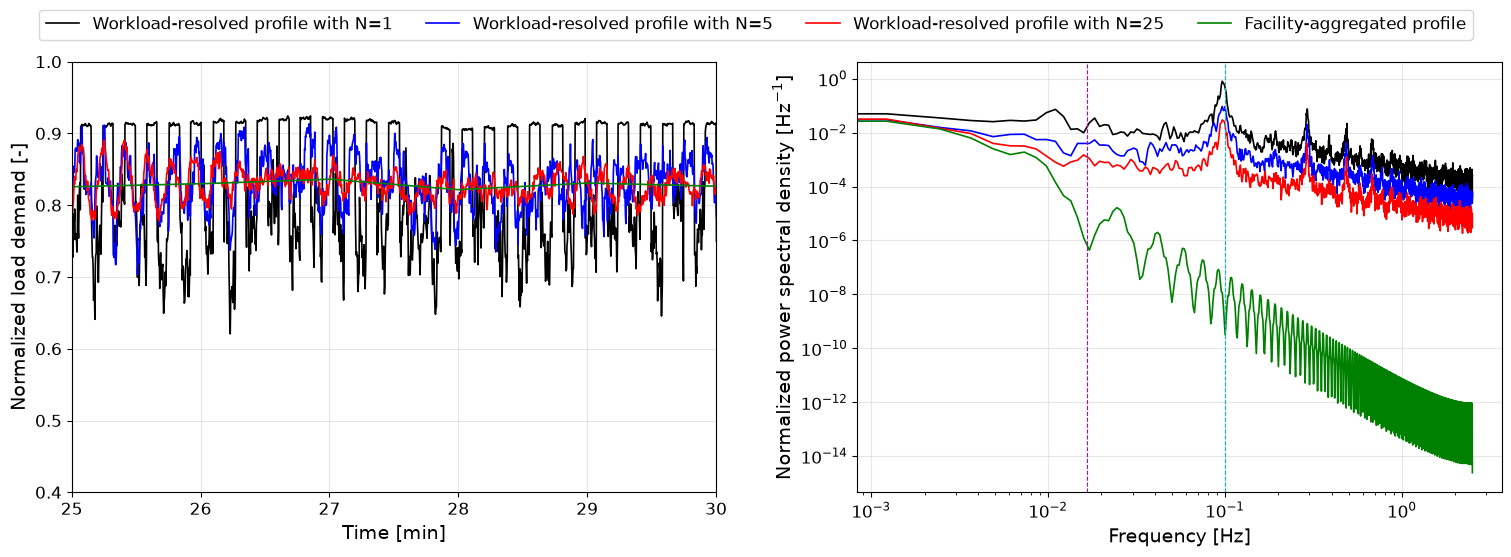

In [7]:
"Generate workload-resolved profile for figure"

plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

time_roi = np.arange(0, TIMEWINDOW*60+dt, dt)
P_annual_worst_dt = P_annual_worst_df.values/P_annual_worst_df.values.max()-0.15  # 0.15 is to keep instantaneous peak power around 1.0
P_annual_worst = np.interp(time_roi, np.arange(0,TIMEWINDOW*60+60,60), P_annual_worst_dt) # 60s -> 0.2s interpolation for base load
trim_edge = int(dt*500) # This is to trim the initial periods
L_worst = len(P_annual_worst)

fs = 1/dt  # 0.2s resolution
psdSet = []
for obs in observationSet:
    f_original, psd = signal.welch(obs/obs.mean(), fs=fs, nperseg=4096)
    psdSet.append(psd)
psd_original = np.mean(psdSet, axis=0)  # Average of 21 sets

f_annual, psd_annual = signal.welch(P_annual_worst/P_annual_worst.mean(), fs, nperseg=4096)

figs, axs = plt.subplots(1,2, figsize=(15,5), constrained_layout=True)
figs.set_constrained_layout_pads(wspace=0.06)

colors = ["k", "b", "r"]
for i, aggNum in enumerate([1, 5, 25]):
  delta_llama2 = generate_fast(N=aggNum, L=L_worst+trim_edge, means=meanAvg, stds=stdAvg,
                      tmat=tranMatAvg, dur_mat=durMatAvg, dt=dt, theta=0.8, seedNum=5, allowedStates=[1,2])
  delta_llama2 = delta_llama2[trim_edge:]
  P_llama2 = P_annual_worst*(1+delta_llama2)  # delta is relative variations
  f_llama2, psd_llama2 = signal.welch(P_llama2/P_llama2.mean(), fs, nperseg=4096)
  f_delta_llama2, psd_delta_llama2 = signal.welch(delta_llama2, fs, nperseg=4096)

  axs[0].plot(time_roi/60, P_llama2, lw=1.2, color=colors[i], label=f"Workload-resolved profile with N={aggNum}")
  axs[1].loglog(f_llama2, psd_llama2, lw=1.2, color=colors[i], label=f"Workload-resolved profile with N={aggNum}")

axs[0].plot(time_roi/60, P_annual_worst, lw=1.2, color="g", label="Facility-aggregated profile")
axs[0].set_xlim([25,30])
axs[0].set_ylim([0.4,1])
axs[0].set_xlabel("Time [min]")
axs[0].set_ylabel("Normalized load demand [-]")
axs[0].grid(alpha=0.3)

axs[1].loglog(f_annual, psd_annual, lw=1.2, color="g", label='Facility-aggregated profile')
axs[1].axvline(1/10, color='c', lw=0.8, ls='--')
axs[1].axvline(1/60, color='m', lw=0.8, ls='--')
axs[1].set_xlabel('Frequency [Hz]'); plt.ylabel('Normalized power spectral density [Hz$^{-1}$]')
axs[1].grid(alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
figs.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.1),
    ncol=4,
    frameon=True,
)
# figs.savefig("signal_N.pdf", bbox_inches="tight")

In [16]:
"Generate actual workload-resolved profile for analysis"

aggNum = 5  # This also affects subsequent std/energy singals!
time_roi = np.arange(0, TIMEWINDOW*60+dt, dt)
P_annual_worst_dt = P_annual_worst_df.values/P_annual_worst_df.values.max()-0.15  # 0.15 is to keep instantaneous peak power around 1.0
P_annual_worst = np.interp(time_roi, np.arange(0,TIMEWINDOW*60+60,60), P_annual_worst_dt)

trim_edge = int(dt*500) # This is to trim the initial periods
L_worst = len(P_annual_worst)
delta_llama2 = generate_fast(N=aggNum, L=L_worst+trim_edge, means=meanAvg, stds=stdAvg,
                      tmat=tranMatAvg, dur_mat=durMatAvg, dt=dt, theta=0.8, seedNum=5, allowedStates=[1,2])
delta_llama2 = delta_llama2[trim_edge:] # Synthetic fast fluctuations
P_llama2 = P_annual_worst*(1+delta_llama2)  # Fianl workload-resolved profile. delta is relative variations
f_llama2, psd_llama2 = signal.welch(P_llama2 / P_llama2.mean(), fs, nperseg=4096)

# RMS
Aeq_llama2 = np.sqrt(2)*np.sqrt(np.mean(delta_llama2**2))
print(f"Equivalent amplitude of reconstructed signal with N={aggNum}: {Aeq_llama2*100:.1f}")

Equivalent amplitude of reconstructed signal with N=5: 6.1


In [17]:
"Generate std/energy matched signals"

f_high = 1/10
f_low = 1/60

idx_hpf_llama2 = f_delta_llama2 >= f_high
idx_bpf_llama2 = (f_delta_llama2 >= f_low) & (f_delta_llama2 < f_high)

energy_hpf_llama2 = np.trapezoid(psd_delta_llama2[idx_hpf_llama2], f_delta_llama2[idx_hpf_llama2])
energy_bpf_llama2 = np.trapezoid(psd_delta_llama2[idx_bpf_llama2], f_delta_llama2[idx_bpf_llama2])
print(
        f"energy in high-freq_llama2: {energy_hpf_llama2:.6f}\n",
        f"energy in band-freq_llama2: {energy_bpf_llama2:.6f}\n",
)

sos_hpf_llama2 = signal.butter(N=4,Wn=f_high, btype='highpass', fs=fs, output='sos')
sos_bpf_llama2 = signal.butter(N=4,Wn=[f_low, f_high], btype='bandpass', fs=fs, output='sos')

band_hpf_llama2 = signal.sosfiltfilt(sos_hpf_llama2, delta_llama2)
band_bpf_llama2 = signal.sosfiltfilt(sos_bpf_llama2, delta_llama2)
bands = {
    "band_hpf_llama2": band_hpf_llama2,
    "band_bpf_llama2": band_bpf_llama2,
}

# full variance reductions when filter is applied
var0_llama2 = np.var(delta_llama2)
var_diff_llama2 = {
    "hpf_llama2": var0_llama2-np.var(delta_llama2-band_hpf_llama2),
    "bpf_llama2": var0_llama2-np.var(delta_llama2-band_bpf_llama2),
}
diff_target_llama2 = min(var_diff_llama2.values())

# Find coefficients to have same removed energy
def FindAlpha(alpha, band, delta, var0, diff_target):
        delta_filt = delta-alpha*band
        reduction = var0-np.var(delta_filt)
        return reduction-diff_target

alpha_hpf_llama2 = brentq(FindAlpha, 0, 1, args=(band_hpf_llama2, delta_llama2, var0_llama2, diff_target_llama2))
alpha_bpf_llama2 = brentq(FindAlpha, 0, 1, args=(band_bpf_llama2, delta_llama2, var0_llama2, diff_target_llama2))
print(
        f"alpha in high-freq_llama2: {alpha_hpf_llama2:.3f}\n",
        f"alpha in band-freq_llama2: {alpha_bpf_llama2:.3f}\n",
)

# std/energy matched fast fluctuations
delta_hfm_std_llama2 = delta_llama2 - band_hpf_llama2
delta_hfm_std_llama2 *= np.std(delta_llama2)/np.std(delta_hfm_std_llama2)   # std-matched case
delta_hfm_energy_llama2 = delta_llama2 - alpha_hpf_llama2 * band_hpf_llama2 # energy-matached case

delta_bfm_std_llama2 = delta_llama2 - band_bpf_llama2
delta_bfm_std_llama2 *= np.std(delta_llama2)/np.std(delta_bfm_std_llama2)
delta_bfm_energy_llama2 = delta_llama2 - alpha_bpf_llama2 * band_bpf_llama2

# std/energy matched final signals
P_hfm_std_llama2 = P_annual_worst * (1+delta_hfm_std_llama2)
P_bfm_std_llama2 = P_annual_worst * (1+delta_bfm_std_llama2)
P_hfm_energy_llama2 = P_annual_worst * (1+delta_hfm_energy_llama2)
P_bfm_energy_llama2 = P_annual_worst * (1+delta_bfm_energy_llama2)

f_hfm_energy_llama2, psd_hfm_energy_llama2 = signal.welch(P_hfm_energy_llama2/P_hfm_energy_llama2.mean(), fs, nperseg=4096)
f_bfm_energy_llama2, psd_bfm_energy_llama2 = signal.welch(P_bfm_energy_llama2/P_bfm_energy_llama2.mean(), fs, nperseg=4096)
f_hfm_std_llama2, psd_hfm_std_llama2 = signal.welch(P_hfm_std_llama2/P_hfm_std_llama2.mean(), fs, nperseg=4096)
f_bfm_std_llama2, psd_bfm_std_llama2 = signal.welch(P_bfm_std_llama2/P_bfm_std_llama2.mean(), fs, nperseg=4096)

energy in high-freq_llama2: 0.000848
 energy in band-freq_llama2: 0.000818

alpha in high-freq_llama2: 0.647
 alpha in band-freq_llama2: 1.000



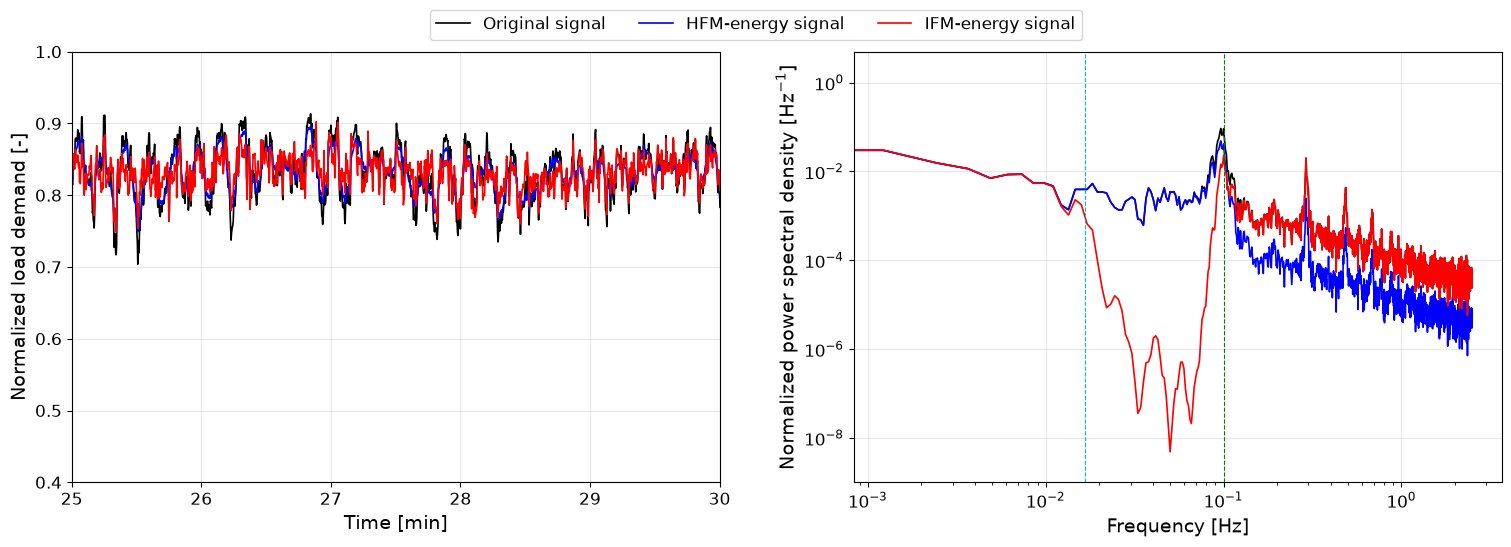

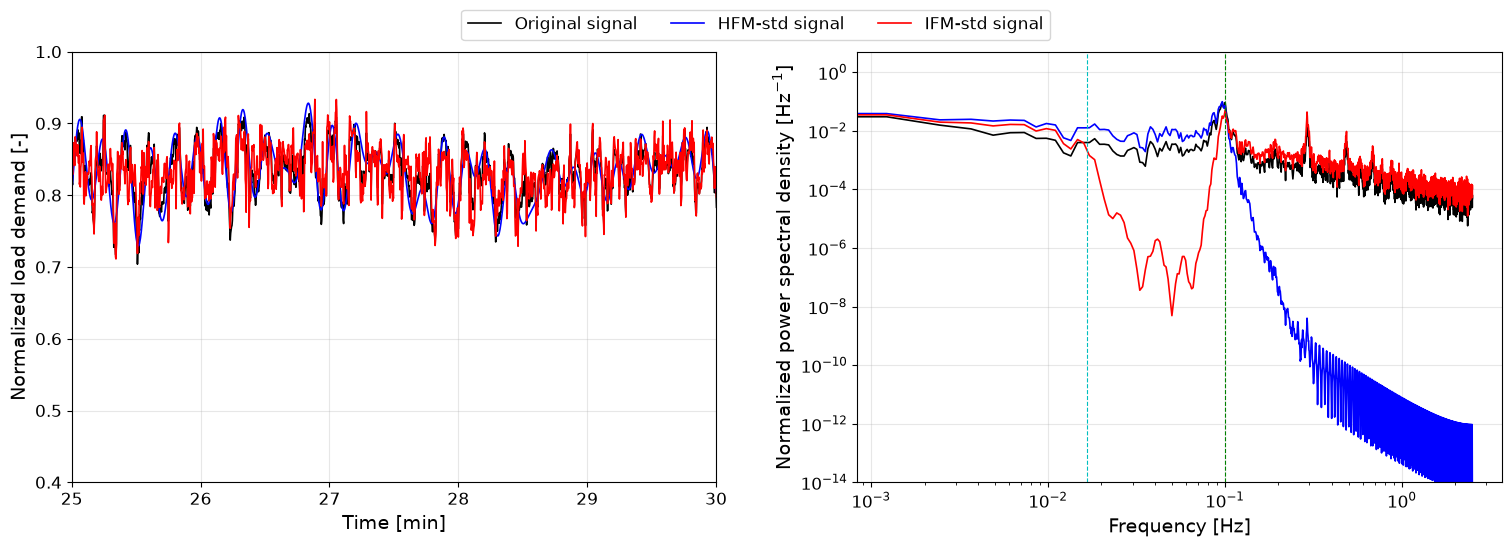

In [18]:
"Generate std/energy matched figure"

# Equal energy-removal plot
plt.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

figs, axs = plt.subplots(1,2, figsize=(15,5), constrained_layout=True)
figs.set_constrained_layout_pads(wspace=0.06)
axs[0].plot(time_roi/60, P_llama2, lw=1.2, color="k", label="Original signal")
axs[0].plot(time_roi/60, P_hfm_energy_llama2, lw=1.2, color="b", label="HFM-energy signal")
axs[0].plot(time_roi/60, P_bfm_energy_llama2, lw=1.2, color="r", label="IFM-energy signal")
axs[0].set_xlabel("Time [min]")
axs[0].set_ylabel("Normalized load demand [-]")
axs[0].set_xlim([25,30])
axs[0].set_ylim([0.4,1])
axs[0].grid(alpha=0.3)

axs[1].loglog(f_llama2, psd_llama2, lw=1.2, color="k", label="Original signal")
axs[1].loglog(f_hfm_energy_llama2, psd_hfm_energy_llama2, lw=1.2, color="b", label="HFM-energy signal")
axs[1].loglog(f_bfm_energy_llama2, psd_bfm_energy_llama2, lw=1.2, color="r", label="IFM-energy signal")
axs[1].axvline(f_high, color='g', lw=0.8, ls='--')
axs[1].axvline(f_low, color='c', lw=0.8, ls='--')
axs[1].set_xlabel('Frequency [Hz]')
axs[1].set_ylabel('Normalized power spectral density [Hz$^{-1}$]')
axs[1].set_ylim([10**-9, 5])
axs[1].grid(alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
figs.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=4,
    frameon=True,
)
# figs.savefig("signal_energy.pdf", bbox_inches="tight")

# Equal std plot
figs, axs = plt.subplots(1,2, figsize=(15,5), constrained_layout=True)
figs.set_constrained_layout_pads(wspace=0.06)
axs[0].plot(time_roi/60, P_llama2, lw=1.2, color="k", label="Original signal")
axs[0].plot(time_roi/60, P_hfm_std_llama2, lw=1.2, color="b", label="HFM-std signal")
axs[0].plot(time_roi/60, P_bfm_std_llama2, lw=1.2, color="r", label="IFM-std signal")
axs[0].set_xlabel("Time [min]")
axs[0].set_ylabel("Normalized load demand [-]")
axs[0].set_xlim([25,30])
axs[0].set_ylim([0.4,1])
axs[0].grid(alpha=0.3)

axs[1].loglog(f_llama2, psd_llama2, lw=1.2, color="k", label="Original signal")
axs[1].loglog(f_hfm_std_llama2, psd_hfm_std_llama2, lw=1.2, color="b", label="HFM-std signal")
axs[1].loglog(f_bfm_std_llama2, psd_bfm_std_llama2, lw=1.2, color="r", label="IFM-std signal")
axs[1].axvline(f_high, color='g', lw=0.8, ls='--')
axs[1].axvline(f_low, color='c', lw=0.8, ls='--')
axs[1].set_xlabel('Frequency [Hz]')
axs[1].set_ylabel('Normalized power spectral density [Hz$^{-1}$]')
axs[1].set_ylim([10**-14, 5])
axs[1].grid(alpha=0.3)

handles, labels = axs[0].get_legend_handles_labels()
figs.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=4,
    frameon=True,
)
# figs.savefig("signal_std.pdf", bbox_inches="tight")

In [12]:
"Generate OpenModelica table input"

timeOM = np.arange(0, 3600+dt, dt)
n = len(timeOM)

with open(f'N_{aggNum}_llama2.txt', 'w', newline="\n") as f:
    f.write("#1\t\n")
    f.write(f"double LoadData({n},2)\n")
    for t, v in zip(timeOM, P_llama2):
        f.write(f"{t:g}\t{v:g}\n")

with open(f'N_{aggNum}_hfm_std_llama2.txt', 'w', newline="\n") as f:
    f.write("#1\t\n")
    f.write(f"double LoadData({n},2)\n")
    for t, v in zip(timeOM, P_hfm_std_llama2):
        f.write(f"{t:g}\t{v:g}\n")

with open(f'N_{aggNum}_bfm_std_llama2.txt', 'w', newline="\n") as f:
    f.write("#1\t\n")
    f.write(f"double LoadData({n},2)\n")
    for t, v in zip(timeOM, P_bfm_std_llama2):
        f.write(f"{t:g}\t{v:g}\n")

with open(f'N_{aggNum}_hfm_energy_llama2.txt', 'w', newline="\n") as f:
    f.write("#1\t\n")
    f.write(f"double LoadData({n},2)\n")
    for t, v in zip(timeOM, P_hfm_energy_llama2):
        f.write(f"{t:g}\t{v:g}\n")

with open(f'N_{aggNum}_bfm_energy_llama2.txt', 'w', newline="\n") as f:
    f.write("#1\t\n")
    f.write(f"double LoadData({n},2)\n")
    for t, v in zip(timeOM, P_bfm_energy_llama2):
        f.write(f"{t:g}\t{v:g}\n")